# 📊 Exploratory Data Analysis on Retail Sales Data

**Internship:** Oasis Infobyte (OIBSIP)  
**Track:** Data Analytics  
**Level:** Level 1  
**Task:** Task 1 – EDA on Retail Sales Data

## Objective

Perform exploratory data analysis on retail sales data to identify sales trends, product performance, customer purchasing patterns, and actionable business insights.

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## 1. Import Libraries      2. Load Dataset & Initial Inspection

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/Superstore.csv', encoding='latin1')

# Initial inspection
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types & Non-Null Values:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (9994, 21)

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2013-138688,13-06-2013,17-06-2013,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data Types & Non-Null Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Cod

## 3. Descriptive Statistics

In [5]:
# Select numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Mean
mean_values = df[numeric_cols].mean()

# Median
median_values = df[numeric_cols].median()

# Mode
mode_values = df[numeric_cols].mode().iloc[0]

# Standard Deviation
std_values = df[numeric_cols].std()

# Combine into one table
statistics = pd.DataFrame({
    'Mean': mean_values,
    'Median': median_values,
    'Mode': mode_values,
    'Standard Deviation': std_values
})

statistics

,Mean,Median,Mode,Standard Deviation
Row ID,4997.500000,4997.5000,1.00,2885.163629
Postal Code,55190.379428,56430.5000,10035.00,32063.693350
Sales,229.858001,54.4900,12.96,623.245101
Quantity,3.789574,3.0000,3.00,2.225110
Discount,0.156203,0.2000,0.00,0.206452
Profit,28.656896,8.6665,0.00,234.260108


## 4. Time Series Analysis

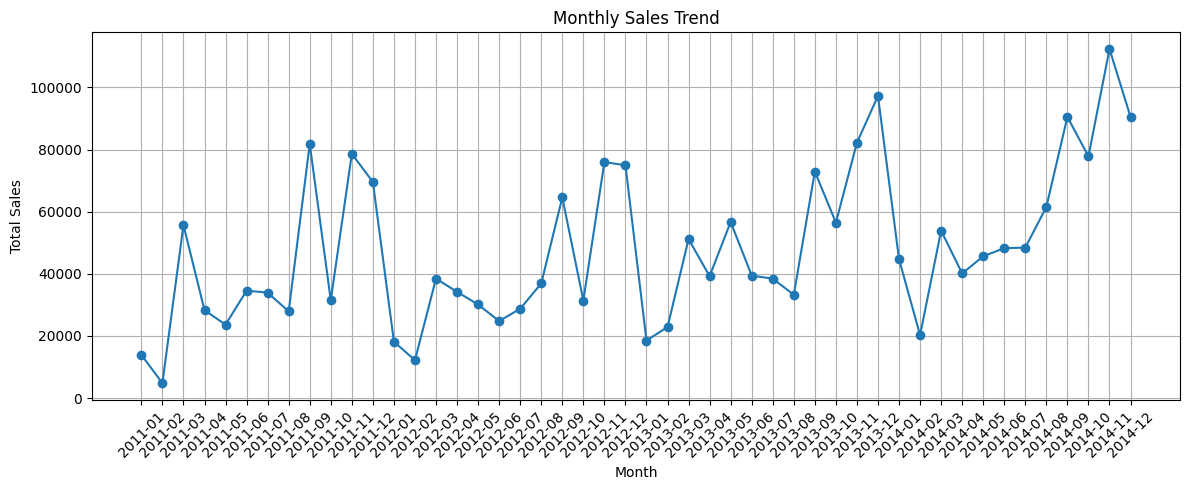

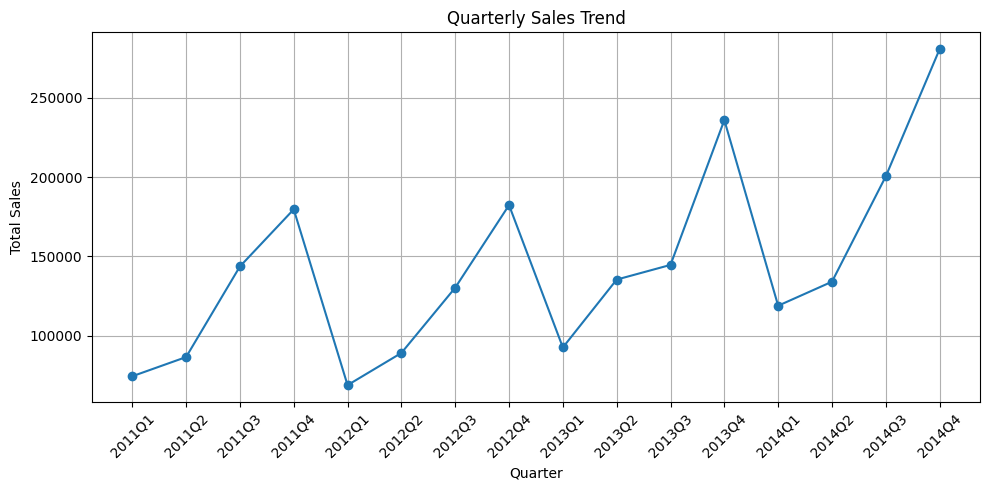

In [7]:
# Convert Order Date to datetime
df['Order Date'] = pd.to_datetime(df['Order Date'],format='%d-%m-%Y')

# Create Month and Quarter columns
df['Month'] = df['Order Date'].dt.to_period('M').astype(str)
df['Quarter'] = df['Order Date'].dt.to_period('Q').astype(str)

# Monthly sales
monthly_sales = df.groupby('Month')['Sales'].sum()

# Quarterly sales
quarterly_sales = df.groupby('Quarter')['Sales'].sum()

# Create two charts
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(quarterly_sales.index, quarterly_sales.values, marker='o')
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation – Sales Trends

The monthly sales trend shows fluctuations in sales performance across different months, with some periods generating higher revenue than others. The quarterly trend also indicates variation in overall sales across quarters. This suggests that sales performance is influenced by seasonal and time-based factors, which can help the business plan inventory and marketing activities more effectively.

In [8]:
# Check customer-related columns
customer_columns = [col for col in df.columns if 'Customer' in col or 'Gender' in col or 'Age' in col]

print("Customer-related columns:")
print(customer_columns)

Customer-related columns:
['Customer ID', 'Customer Name']


## 5. Customer Analysis

In [9]:
# Customer-wise sales analysis

customer_sales = (
    df.groupby('Customer Name')['Sales']
    .sum()
    .sort_values(ascending=False)
)

# Top 10 customers by sales
top_10_customers = customer_sales.head(10)

print("Top 10 Customers by Total Sales:")
display(top_10_customers)

Top 10 Customers by Total Sales:


,Sales
Customer Name,
Sean Miller,25043.050
Tamara Chand,19052.218
Raymond Buch,15117.339
Tom Ashbrook,14595.620
Adrian Barton,14473.571
Ken Lonsdale,14175.229
Sanjit Chand,14142.334
Hunter Lopez,12873.298
Sanjit Engle,12209.438


In [12]:
# Top 10 Customers by Total Profit
top_10_profit_customers = (
    df.groupby('Customer Name')['Profit']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Total Profit:")
display(top_10_profit_customers)

Top 10 Customers by Total Profit:


,Profit
Customer Name,
Tamara Chand,8981.3239
Raymond Buch,6976.0959
Sanjit Chand,5757.4119
Hunter Lopez,5622.4292
Adrian Barton,5444.8055
Tom Ashbrook,4703.7883
Christopher Martinez,3899.8904
Keith Dawkins,3038.6254
Andy Reiter,2884.6208


## 6. Product Analysis

In [13]:
# Top 10 Best-Selling Products

top_10_products = (
    df.groupby('Product Name')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Best-Selling Products:")
display(top_10_products)

Top 10 Best-Selling Products:


,Quantity
Product Name,
Staples,876
KI Adjustable-Height Table,74
Storex Dura Pro Binders,71
Avery Non-Stick Binders,71
GBC Premium Transparent Covers with Diagonal Lined Pattern,67
"Situations Contoured Folding Chairs, 4/Set",64
Chromcraft Round Conference Tables,61
Eldon Wave Desk Accessories,61
Wilson Jones Turn Tabs Binder Tool for Ring Binders,59


### Observation – Top 10 Best-Selling Products

The top-selling products contribute a significant share of the total quantity sold. Identifying these high-demand products can help the business maintain adequate inventory levels, reduce stock-out risk, and focus promotional activities on products with strong customer demand.

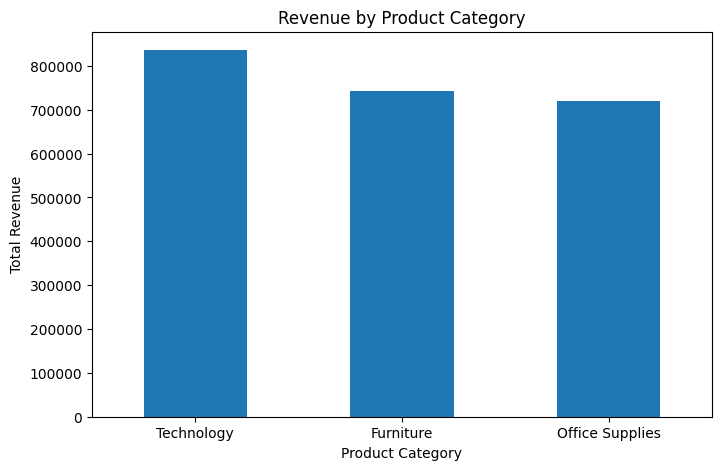

In [14]:
# Revenue by Product Category

category_revenue = (
    df.groupby('Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

category_revenue.plot(
    kind='bar',
    figsize=(8, 5),
    title='Revenue by Product Category'
)

plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

### Observation – Revenue by Product Category

The revenue analysis shows that sales contribution varies across product categories. The category generating the highest revenue represents an important source of business income, while lower-revenue categories may require targeted promotions or product-level analysis to identify growth opportunities.

## 7. Correlation Analysis

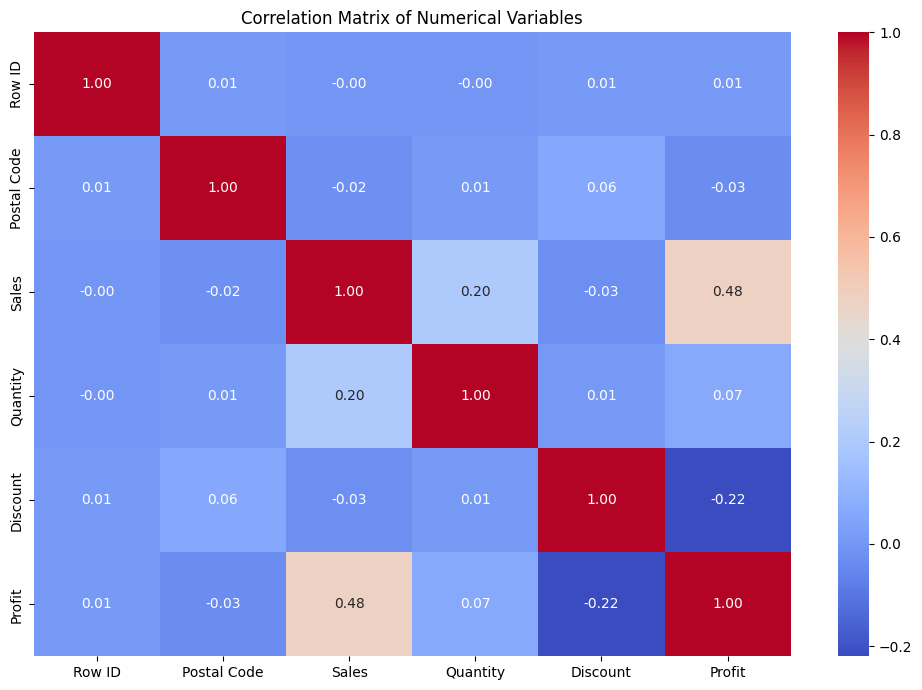

In [15]:
# Correlation Matrix Heatmap

correlation_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

### Observation – Correlation Heatmap

The correlation matrix shows the strength and direction of relationships between the numerical variables. Sales and Profit have a positive relationship, while some other variables show weaker relationships. These relationships can help identify which business variables are associated with higher sales and profitability.

## 8. Additional Business Insight

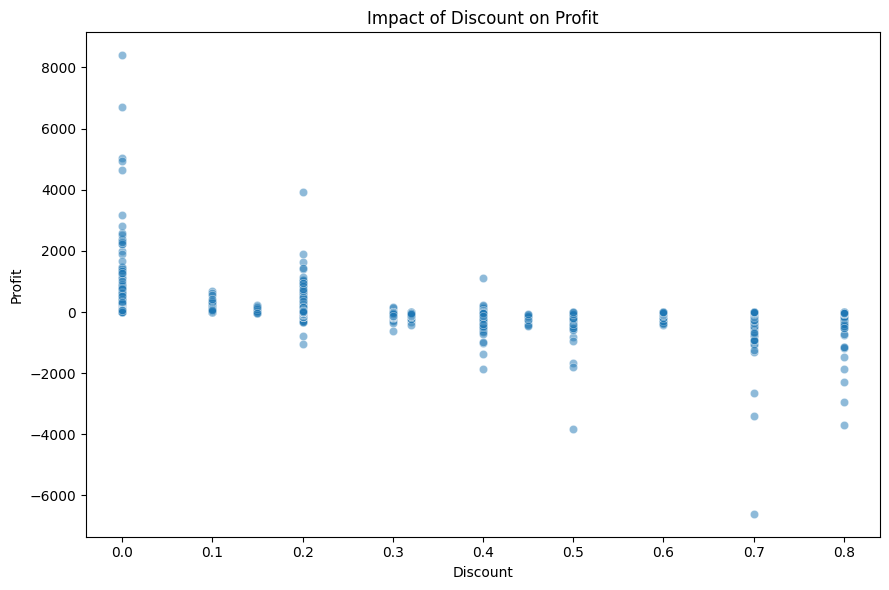

In [16]:
# Additional Visualization: Discount vs Profit

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    alpha=0.5
)

plt.title('Impact of Discount on Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')

plt.tight_layout()
plt.show()

### Observation – Impact of Discount on Profit

The scatter plot shows the relationship between discount levels and profit. Higher discounts are associated with several low-profit and loss-making transactions. This indicates that excessive discounting may reduce profitability and should be applied selectively to protect profit margins.

## 9. Conclusion & Business Recommendations

## Conclusion & Business Recommendations

The exploratory data analysis of the retail sales dataset revealed important patterns in sales performance, product demand, customer purchasing behaviour, and profitability.

### Actionable Business Recommendations

1. **Focus on high-demand products:** Maintain sufficient inventory of the top-selling products to reduce stock-outs and meet customer demand.

2. **Prioritise high-revenue categories:** Allocate marketing and inventory resources to the product categories generating the highest revenue, while analysing lower-performing categories for improvement opportunities.

3. **Control excessive discounting:** The analysis indicates that higher discounts can be associated with lower profits and losses. The business should use discounts selectively and monitor their impact on profit margins.

4. **Use seasonal sales patterns:** Monthly and quarterly sales trends can be used to improve inventory planning, promotional campaigns, and sales forecasting during high-demand periods.